In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

#### Building the dataset
A dictionary-based dataset will be constructed using the .dat files output from the simulation. Important things to consider for users: the algorithm relies on .dat files following a specific naming convention in `obs_K_{k}_r0_{r0}_seed_{seed}.dat`.

The initial dictionary can be accessed using the folder name key e.g.:
dat_files_dict['fd_push_full_rod_dats']
A specific data set can be retrieved using:
dat_files_dict['fd_push_full_rod_dats'][(k,r0,seed)]

At any time, use .keys() to identify the available data fields at any level in the dictionary. All dictionaries follow a similar organisation.

In [16]:
#### READ SIMULATION OUTPUTS AND APPENDS THEM TO A DICTIONARY OF DATAFRAMES
INPUT_FOLDER = 'fextensions_results'

import re

def extract_parameters_from_filename(filename):
    """
    Extract K, r0, and seed from filename.
    Adjust the regex pattern to match your naming convention.
    
    Common patterns might be:
    - K_<value>_r0_<value>_seed_<value>.dat
    - output_K<value>_r0<value>_seed<value>.dat
    """
    # Try to extract K, r0, and seed using regex
    # Adjust this pattern based on your actual naming convention
    pattern = r'K[_]?(\d+(?:\.\d+)?)[_]?.*r0[_]?(\d+(?:\.\d+)?)[_]?.*seed[_]?(\d+)'
    
    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        K = float(match.group(1))
        r0 = float(match.group(2))
        seed = int(match.group(3))
        return K, r0, seed
    
    # If pattern doesn't match, return None
    return None

# Dictionary to store data from each subfolder
dat_files_dict = {}

# Iterate through subfolders using scandir
for subfolder_entry in os.scandir(INPUT_FOLDER):
    if subfolder_entry.is_dir():
        subfolder_name = subfolder_entry.name
        dat_files_dict[subfolder_name] = {}
        
        # Iterate through files in the subfolder using scandir
        for file_entry in os.scandir(subfolder_entry.path):
            if file_entry.is_file() and file_entry.name.endswith('.dat'):
                try:
                    # Extract parameters from filename
                    params = extract_parameters_from_filename(file_entry.name)
                    
                    if params:
                        K, r0, seed = params
                        
                        # Read the .dat file
                        data = pd.read_csv(file_entry.path, sep='\s+', header=None)
                        
                        # Store with (K, r0, seed) as key
                        dat_files_dict[subfolder_name][(K, r0, seed)] = {
                            'filename': file_entry.name,
                            'data': data,
                            'K': K,
                            'r0': r0,
                            'seed': seed
                        }
                        print(f"Loaded: {subfolder_name}/{file_entry.name} -> K={K}, r0={r0}, seed={seed}")
                    else:
                        print(f"Warning: Could not extract parameters from {file_entry.name}")
                    
                except Exception as e:
                    print(f"Error reading {file_entry.path}: {e}")
        
        # Remove empty subfolder entries
        if len(dat_files_dict[subfolder_name]) == 0:
            del dat_files_dict[subfolder_name]

# Summary
print(f"\n{'='*60}")
print(f"Summary: Found {len(dat_files_dict)} subfolders with .dat files")
print(f"{'='*60}")
for subfolder, files in dat_files_dict.items():
    print(f"{subfolder}: {len(files)} file(s)")
    # Show example parameters
    if files:
        example_key = list(files.keys())[0]
        print(f"  Example access: dat_files_dict['{subfolder}'][{example_key}]")
print(f"{'='*60}")

Loaded: fd_push_full_rod_dats/obs_K_025_r0_10_seed_1.dat -> K=25.0, r0=10.0, seed=1
Loaded: fd_push_full_rod_dats/obs_K_025_r0_10_seed_2.dat -> K=25.0, r0=10.0, seed=2
Loaded: fd_push_full_rod_dats/obs_K_025_r0_10_seed_3.dat -> K=25.0, r0=10.0, seed=3
Loaded: fd_push_full_rod_dats/obs_K_025_r0_10_seed_4.dat -> K=25.0, r0=10.0, seed=4
Loaded: fd_push_full_rod_dats/obs_K_025_r0_10_seed_5.dat -> K=25.0, r0=10.0, seed=5
Loaded: fd_push_full_rod_dats/obs_K_025_r0_10_seed_6.dat -> K=25.0, r0=10.0, seed=6
Loaded: fd_push_full_rod_dats/obs_K_025_r0_10_seed_7.dat -> K=25.0, r0=10.0, seed=7
Loaded: fd_push_full_rod_dats/obs_K_025_r0_11_seed_1.dat -> K=25.0, r0=11.0, seed=1
Loaded: fd_push_full_rod_dats/obs_K_025_r0_11_seed_2.dat -> K=25.0, r0=11.0, seed=2
Loaded: fd_push_full_rod_dats/obs_K_025_r0_11_seed_3.dat -> K=25.0, r0=11.0, seed=3
Loaded: fd_push_full_rod_dats/obs_K_025_r0_11_seed_4.dat -> K=25.0, r0=11.0, seed=4
Loaded: fd_push_full_rod_dats/obs_K_025_r0_11_seed_5.dat -> K=25.0, r0=11.0,

In [27]:
#### TESTING OUT DICTIONARY CONTENTS AND ACCESSIBILITY
print(dat_files_dict.keys())
test = dat_files_dict['fd_push_full_rod_dats'][(25, 3, 1)]
print(test.keys())

dict_keys(['fd_push_full_rod_dats', 'fd_push_half_rod_dats'])
dict_keys(['filename', 'data', 'K', 'r0', 'seed'])


#### Calculating steady state regions via manual cutoff

In [28]:
CUTOFF = 2.5e7  # 2,500,000

# Create new dictionary for steady-state filtered data
ss_dat_files_dict = {}

# Iterate through all subfolders
for subfolder_name, files_dict in dat_files_dict.items():
    ss_dat_files_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        # Apply cutoff filter (assuming first column is step)
        # Adjust column index if your step column is different
        df_filtered = df[df.iloc[:, 0] >= CUTOFF].reset_index(drop=True)
        
        # Store filtered data with same structure
        ss_dat_files_dict[subfolder_name][(K, r0, seed)] = {
            'filename': file_info['filename'],
            'data': df_filtered,
            'K': K,
            'r0': r0,
            'seed': seed
        }
        
        print(f"Filtered {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} -> {len(df_filtered)} rows")

# Summary
print(f"\n{'='*60}")
print(f"Cutoff filtering complete!")
print(f"Applied cutoff: step >= {CUTOFF}")
print(f"Processed {sum(len(files) for files in ss_dat_files_dict.values())} datasets")
print(f"{'='*60}")

Filtered fd_push_full_rod_dats (K=25.0, r0=10.0, seed=1): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=10.0, seed=2): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=10.0, seed=3): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=10.0, seed=4): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=10.0, seed=5): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=10.0, seed=6): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=10.0, seed=7): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=11.0, seed=1): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=11.0, seed=2): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=11.0, seed=3): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=11.0, seed=4): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=11.0, seed=5): 50031 -> 27002 rows
Filtered fd_push_full_rod_dats (K=25.0, r0=11.0, seed=6): 50031 

#### Computing statistics for each simulation

In [30]:
# Dictionary to store statistics for each simulation
stats_dict = {}

# Column indices (adjust based on your .dat file structure)
# Assuming columns are: [step, dist, force_mag, hbond, ...]
COL_STEP = 0
COL_DIST = 1
COL_FORCE_MAG = 2
COL_HBOND = 3

# Iterate through all subfolders
for subfolder_name, files_dict in ss_dat_files_dict.items():
    stats_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        if len(df) == 0:
            print(f"Warning: Empty dataframe for {subfolder_name} (K={K}, r0={r0}, seed={seed})")
            continue
        
        # Extract columns as numpy arrays
        dist = df.iloc[:, COL_DIST].to_numpy()
        force_mag = df.iloc[:, COL_FORCE_MAG].to_numpy()
        hbond = df.iloc[:, COL_HBOND].to_numpy()
        
        # Calculate signed force: +|F| if dist > r0, -|F| if dist < r0
        signed_force = np.sign(dist - r0) * force_mag
        
        # Compute statistics
        stats_dict[subfolder_name][(K, r0, seed)] = {
            'K': K,
            'r0': r0,
            'seed': seed,
            'filename': file_info['filename'],
            
            # Signed force statistics
            'F_mean': signed_force.mean(),
            'F_std': signed_force.std(ddof=0),
            
            # Force magnitude statistics
            'force_mag_mean': force_mag.mean(),
            'force_mag_std': force_mag.std(ddof=0),
            
            # Distance statistics
            'dist_mean': dist.mean(),
            'dist_std': dist.std(ddof=0),
            
            # Hydrogen bond statistics
            'hbond_mean': hbond.mean(),
            'hbond_std': hbond.std(ddof=0),
            
            # Additional info
            'n_samples': len(df)
        }
        
        print(f"Computed stats for {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} samples")

# Summary
print(f"\n{'='*60}")
print(f"Statistics computation complete!")
print(f"Processed {sum(len(files) for files in stats_dict.values())} datasets")
print(f"{'='*60}")

Computed stats for fd_push_full_rod_dats (K=25.0, r0=10.0, seed=1): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=10.0, seed=2): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=10.0, seed=3): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=10.0, seed=4): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=10.0, seed=5): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=10.0, seed=6): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=10.0, seed=7): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=11.0, seed=1): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=11.0, seed=2): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=11.0, seed=3): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=11.0, seed=4): 27002 samples
Computed stats for fd_push_full_rod_dats (K=25.0, r0=11.0, seed=5): 27002 samples
Computed stats f

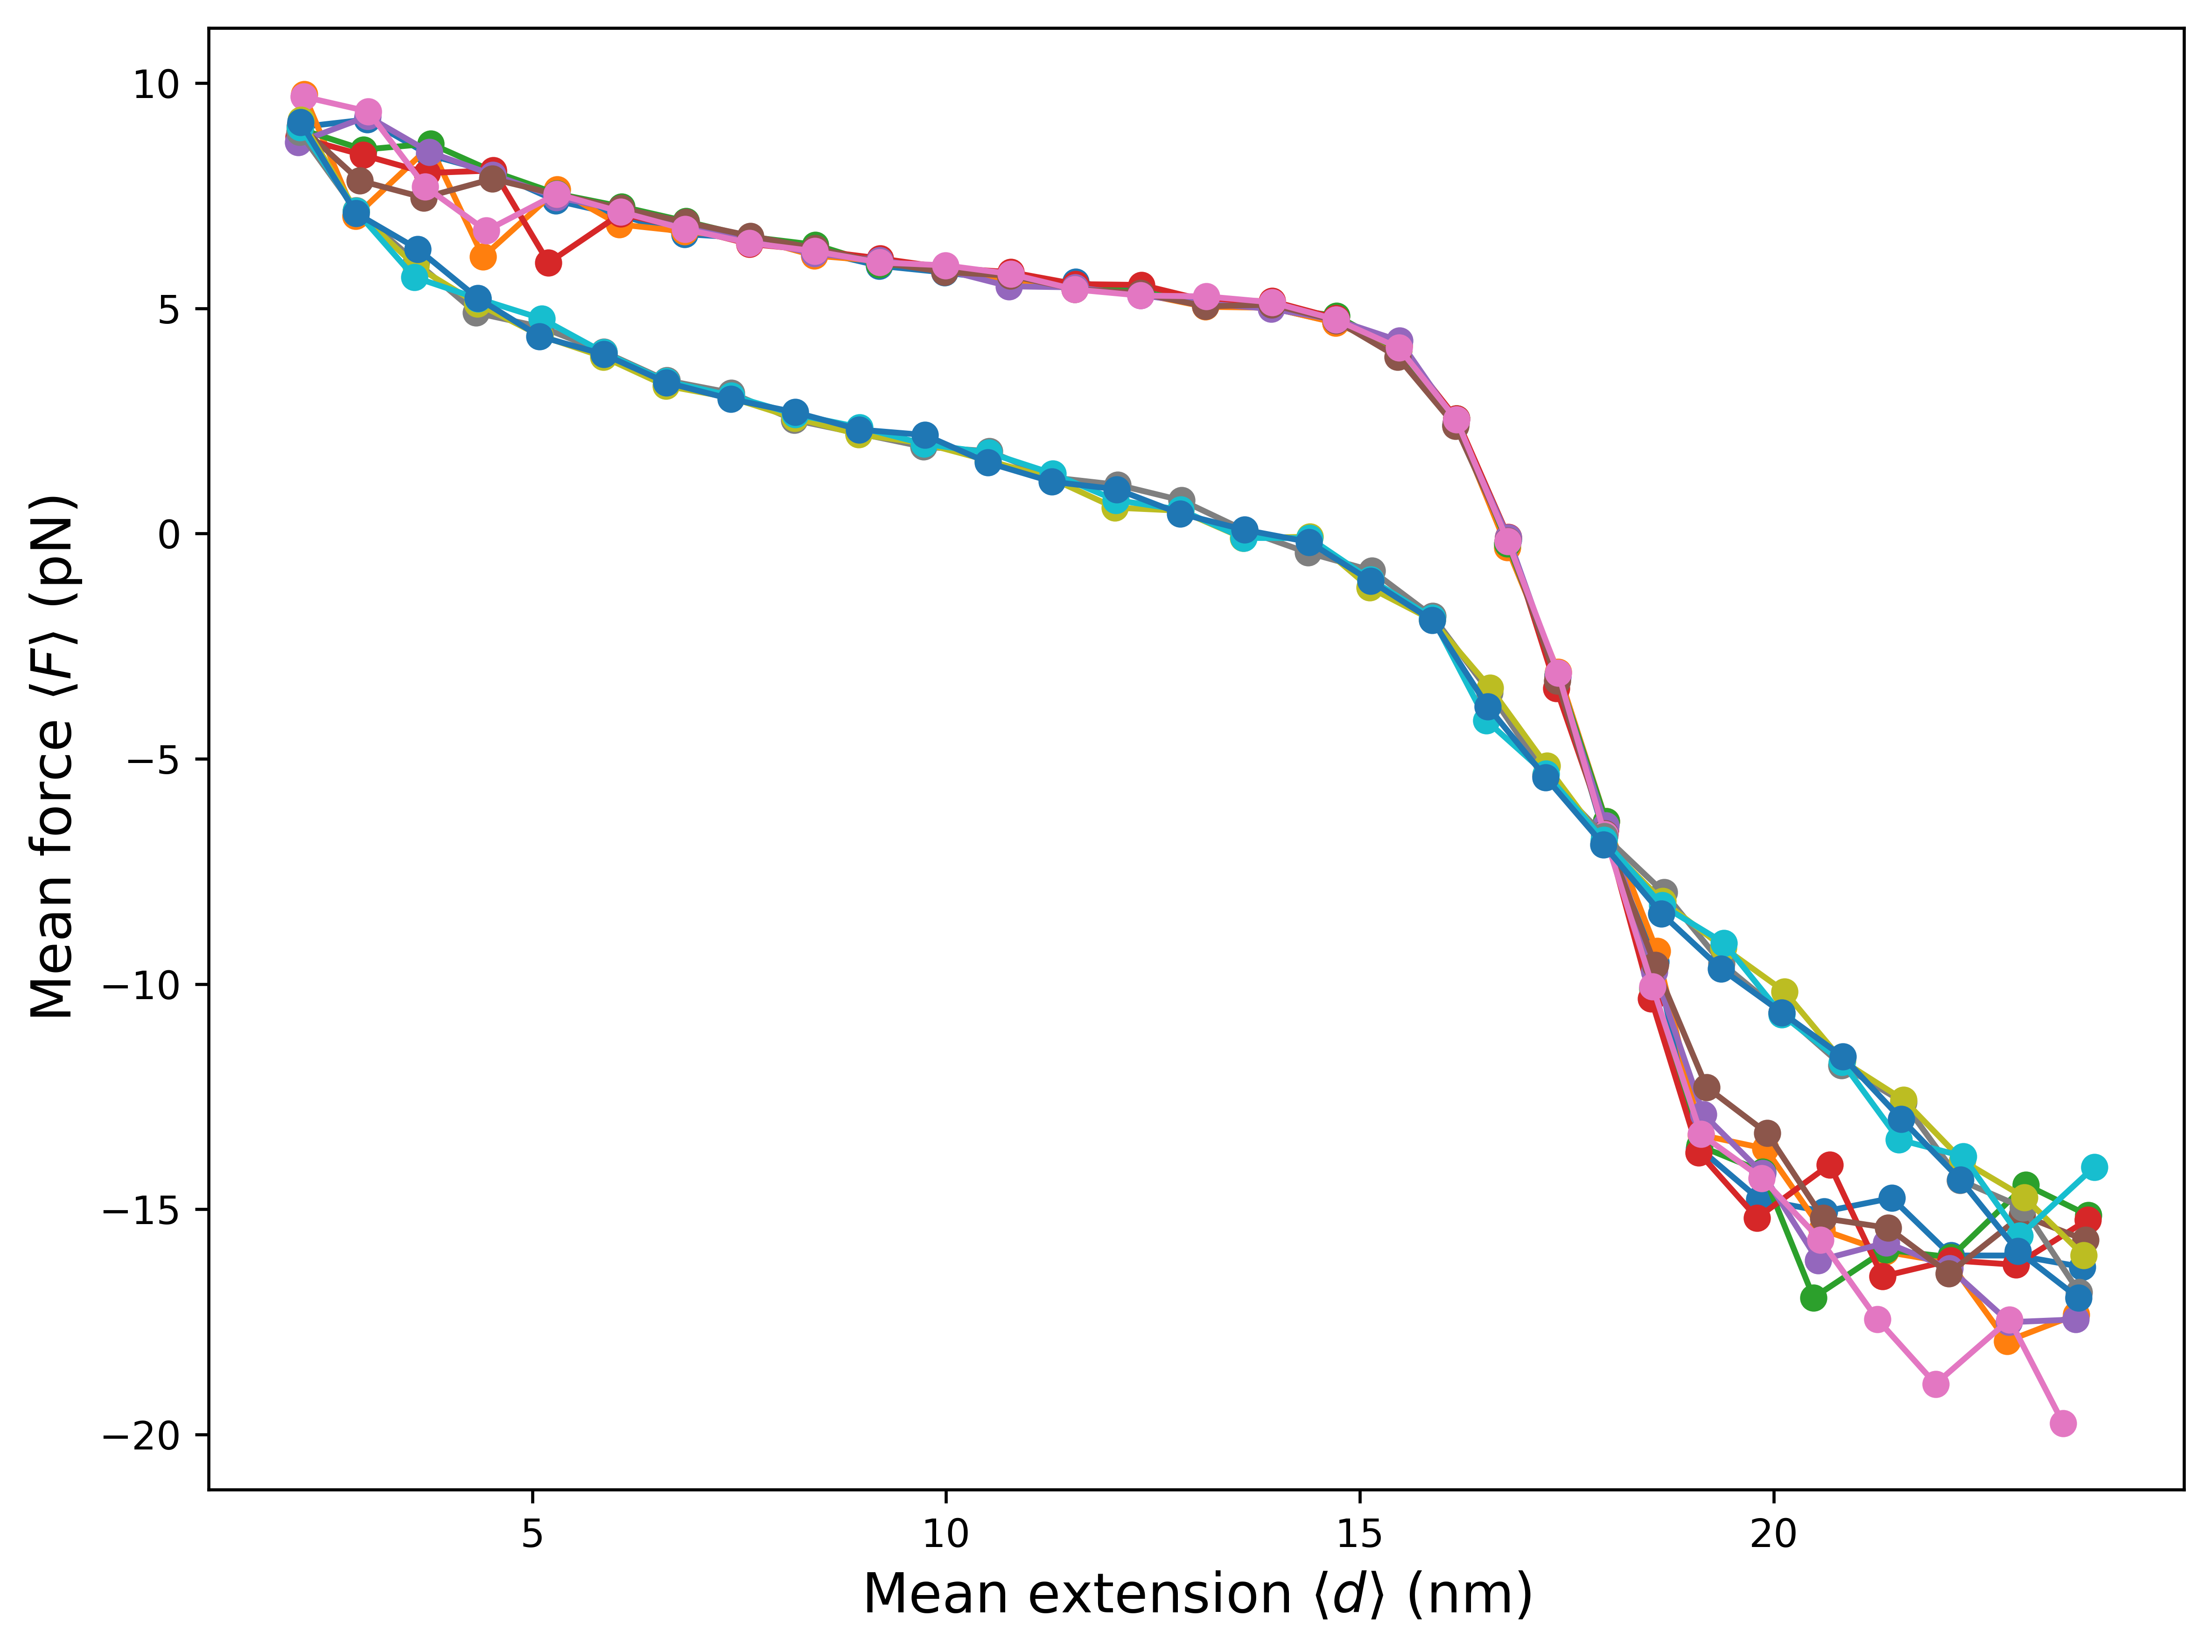

In [36]:
# Unit conversion factors
DIST_CONVERSION = 0.8  # to nm
FORCE_CONVERSION = 48.6  # to pN

fig, ax = plt.subplots(figsize=(8, 6), dpi=600)

# Collect all data points organized by subfolder, K, and seed
for subfolder_name, files_dict in stats_dict.items():
    # Organize data by (K, seed) for proper plotting
    data_by_k_seed = {}
    
    for (K, r0, seed), stats in files_dict.items():
        key = (K, seed)
        if key not in data_by_k_seed:
            data_by_k_seed[key] = []
        
        # Append (r0, dist_mean, F_mean) for this simulation
        data_by_k_seed[key].append({
            'r0': r0,
            'dist_mean': stats['dist_mean'],
            'F_mean': stats['F_mean']
        })
    
    # Plot each (K, seed) combination
    for (K, seed), data_points in data_by_k_seed.items():
        # Sort by mean distance for connected lines
        data_points = sorted(data_points, key=lambda x: x['dist_mean'])
        
        # Extract values
        dist_means = [DIST_CONVERSION * d['dist_mean'] for d in data_points]
        F_means = [FORCE_CONVERSION * d['F_mean'] for d in data_points]
        
        # Plot with label
        ax.plot(dist_means, F_means, marker='o', 
                label=f"{subfolder_name}, K={K}, seed={seed}", 
                linewidth=1.5, markersize=6)

ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)", fontsize=14)
ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)", fontsize=14)
#ax.legend(fontsize=10, bbox_to_anchor=(1.05, 1), loc='upper left')
#ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()